In [1]:
import kagglehub
path = kagglehub.dataset_download("sulianova/cardiovascular-disease-dataset")
print("Path to dataset files:", path)

Using Colab cache for faster access to the 'cardiovascular-disease-dataset' dataset.
Path to dataset files: /kaggle/input/cardiovascular-disease-dataset


In [2]:
# !pip install shap xgboost
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import shap

In [3]:
df = pd.read_csv(os.path.join(path, "cardio_train.csv"), sep=';')
print("Shape of dataset:", df.shape)
df.head()

Shape of dataset: (70000, 13)


,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
0,0,18393,2,168,62.0,110,80,1,1,0,0,1,0
1,1,20228,1,156,85.0,140,90,3,1,0,0,1,1
2,2,18857,1,165,64.0,130,70,3,1,0,0,0,1
3,3,17623,2,169,82.0,150,100,1,1,0,0,1,1
4,4,17474,1,156,56.0,100,60,1,1,0,0,0,0


In [4]:
df = df.drop(columns=['id'], errors='ignore')
print("Missing values:\n", df.isnull().sum())

X = df.drop(columns=['cardio'])
y = df['cardio']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

Missing values:
 age            0
gender         0
height         0
weight         0
ap_hi          0
ap_lo          0
cholesterol    0
gluc           0
smoke          0
alco           0
active         0
cardio         0
dtype: int64


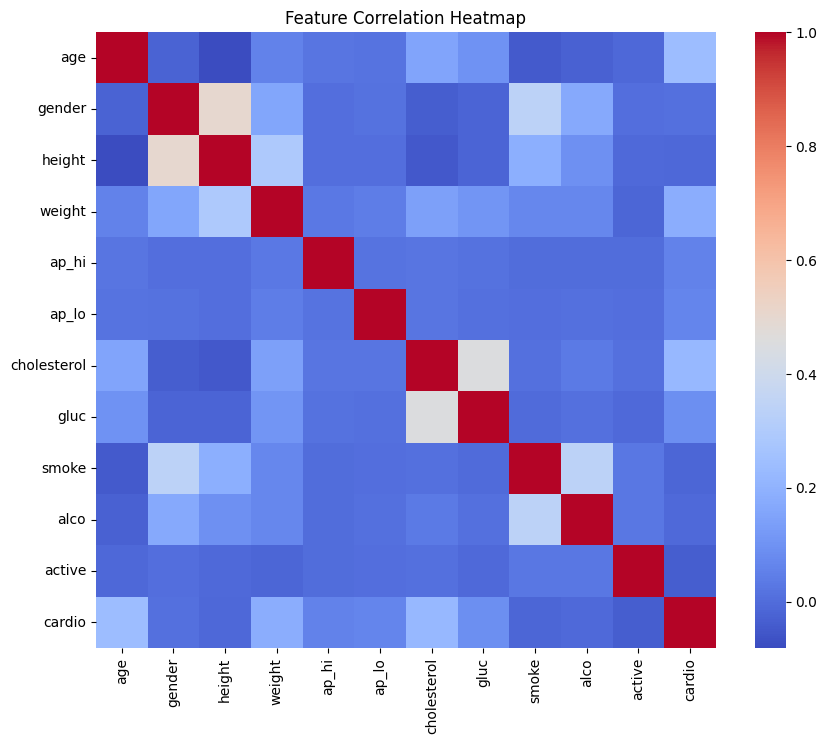

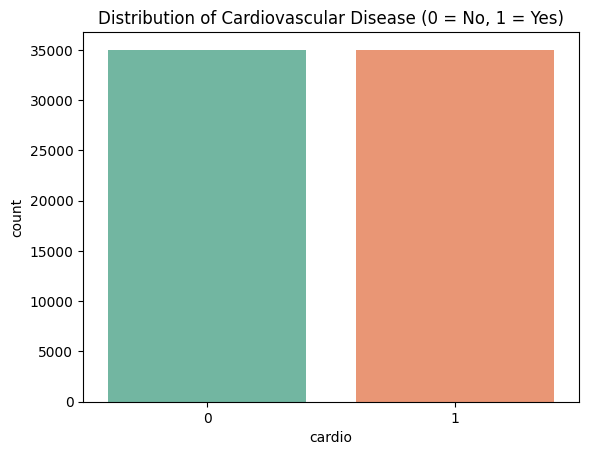

In [5]:
plt.figure(figsize=(10,8))
sns.heatmap(df.corr(), cmap="coolwarm", annot=False)
plt.title("Feature Correlation Heatmap")
plt.show()

sns.countplot(x='cardio', data=df, hue='cardio', palette='Set2', legend=False)
plt.title("Distribution of Cardiovascular Disease (0 = No, 1 = Yes)")
plt.show()

In [6]:
import xgboost as xgb

dtrain = xgb.DMatrix(X_train, label=y_train)
dtest = xgb.DMatrix(X_test, label=y_test)

# Modern XGBoost: tree_method='hist' (+ device='cuda' for GPU; use 'cpu' otherwise)
params = {
    'tree_method': 'hist',
    'device': 'cpu',          # change to 'cuda' on a GPU runtime
    'objective': 'binary:logistic',
    'seed': 42,
    'verbosity': 1
}

num_round = 100
model = xgb.train(params, dtrain, num_round)

y_proba = model.predict(dtest)
y_pred = (y_proba >= 0.5).astype(int)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))

Accuracy: 0.7355

Classification Report:
               precision    recall  f1-score   support

           0       0.72      0.77      0.75      6988
           1       0.76      0.70      0.73      7012

    accuracy                           0.74     14000
   macro avg       0.74      0.74      0.74     14000
weighted avg       0.74      0.74      0.74     14000



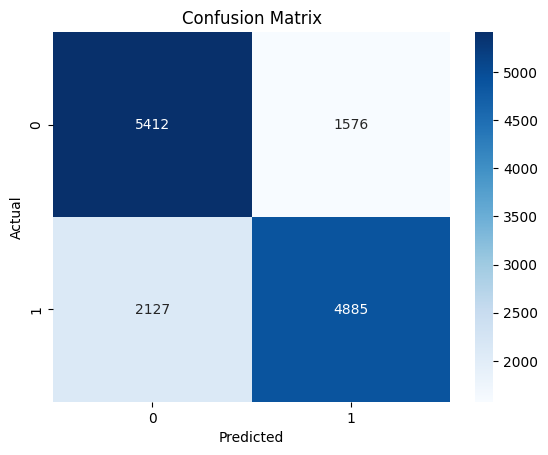

In [7]:
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

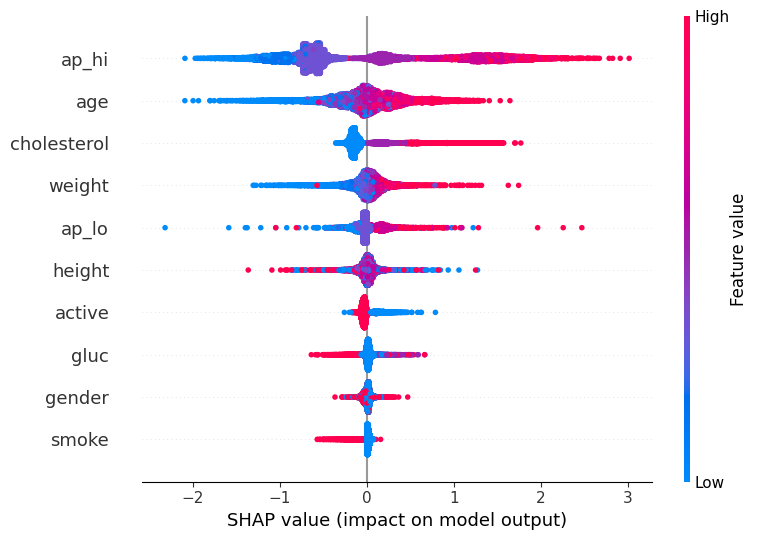

In [8]:
explainer = shap.TreeExplainer(model)

sample_size = 10000 if len(X_test) > 10000 else len(X_test)
sample_indices = np.random.choice(X_test.index, size=sample_size, replace=False)
X_test_sample = X_test.loc[sample_indices]

dtest_sample = xgb.DMatrix(X_test_sample)

shap_values_sample = explainer.shap_values(dtest_sample)

shap.summary_plot(shap_values_sample, X_test_sample, feature_names=X_test.columns, max_display=10)

Predicted: [1]
True label: 1


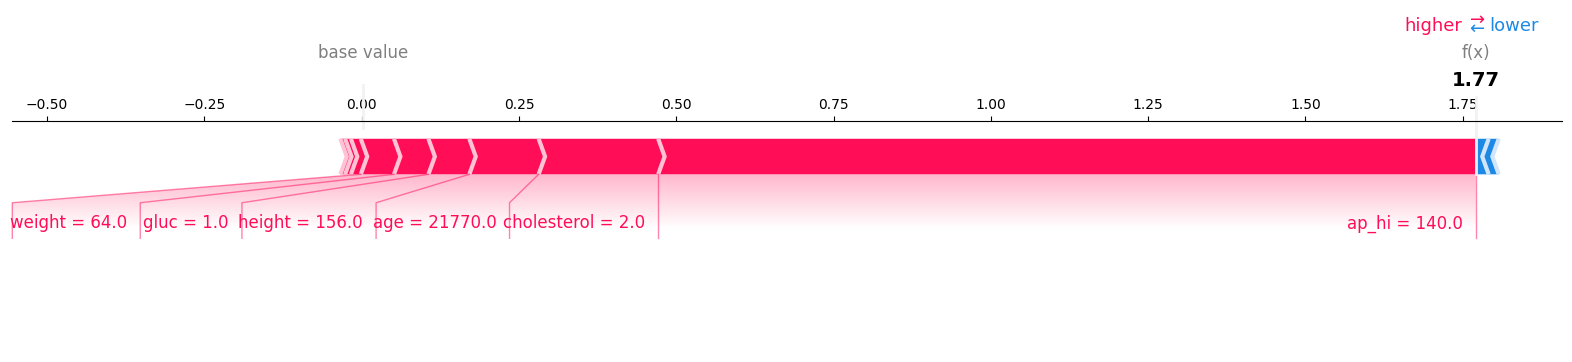

In [9]:
i = 0   # <- change this to explain any test patient

X_test_single = X_test.iloc[[i]]
dtest_single = xgb.DMatrix(X_test_single)

print("Predicted:", (model.predict(dtest_single) >= 0.5).astype(int))
print("True label:", y_test.iloc[i])

shap_values_single = explainer.shap_values(dtest_single)
shap.force_plot(explainer.expected_value, shap_values_single, X_test_single, matplotlib=True)

## 🧾 Post-Lab Questions and Answers

**1. What is Explainable AI, and why is it important in healthcare?**
XAI is a set of techniques that make AI models understandable to humans. In healthcare, models assist critical decisions, so doctors need to know *why* a prediction was made. It builds trust, ensures transparency and accountability, supports ethical and safe decisions, and helps comply with regulations (FDA, GDPR).

**2. How does explainability improve trust between clinicians and AI systems?**
Clinicians can see that the model relies on relevant medical factors (age, blood pressure, cholesterol), which builds confidence, lets them verify reasoning, and makes AI a collaborative partner rather than a black box.

**3. How can clinicians validate explanations?**
Compare feature importance with medical knowledge; use SHAP/LIME visualizations; run case studies or pilots on real patient data; check the model consistently highlights clinically relevant features.

**4. Model-specific vs model-agnostic XAI**
| Type | Description | Examples |
|---|---|---|
| Model-specific | Designed for a model class, uses its internals | SHAP TreeExplainer (tree models), Grad-CAM (CNNs) |
| Model-agnostic | Works on any model | LIME, Permutation Importance |

**Conclusion:** XAI ensures healthcare models are accurate, transparent, interpretable and trustworthy.